In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (2).zip to archive (2) (1).zip


In [3]:

import zipfile
import os

zip_path = "archive (2).zip"
extract_folder = "/content/rainfall_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Extracted files:")
for root, dirs, files in os.walk(extract_folder):
    for file in files:
        print(os.path.join(root, file))


Extracted files:
/content/rainfall_data/Indian Rainfall Dataset District-wise Daily Measurements.csv


In [4]:

import glob
import pandas as pd

csv_files = glob.glob(
    "/content/rainfall_data/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)


CSV files found: ['/content/rainfall_data/Indian Rainfall Dataset District-wise Daily Measurements.csv']


In [5]:

df = pd.read_csv(csv_files[0], sep=";")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (8790, 34)

Column names:
['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0


In [6]:

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nAvailable states:")
print(df["state"].unique()[:20])

print("\nSample districts:")
print(df[["state", "district"]].drop_duplicates().head(20))


Dataset dimensions: (8790, 34)

Column names:
['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']

Missing values per column:
state       0
district    0
month       0
1st         0
2nd         0
3rd         0
4th         0
5th         0
6th         0
7th         0
8th         0
9th         0
10th        0
11th        0
12th        0
13th        0
14th        0
15th        0
16th        0
17th        0
18th        0
19th        0
20th        0
21st        0
22nd        0
23rd        0
24th        0
25th        0
26th        0
27th        0
28th        0
29th        0
30th        0
31st        0
dtype: int64

Available states:
['Andaman & Nicobar' 'Andhra Pradesh' 'Arunachal Pradesh' 'Assam' 'Bihar'
 'Chandigarh' 'Chhattisgarh' 'Dadra & Nagar Haveli' 'Daman & Diu' 'Delhi'


In [7]:

df["state"] = df["state"].astype(str).str.strip()
df["district"] = df["district"].astype(str).str.strip()

district_data = df[
    (df["state"].str.contains("Tamil Nadu", case=False, na=False)) &
    (df["district"].str.contains("Coimbatore", case=False, na=False))
]

print("Matching rows:", len(district_data))
display(district_data.head())


Matching rows: 12


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
546,Tamil Nadu,Coimbatore,1,2.14889,9.11014,0.046436,0.000000,0.000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.164271,0.073029,0.000000,0.000000,0.000000
1278,Tamil Nadu,Coimbatore,2,0.00000,0.00000,0.000000,0.074003,0.000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.020852,0.000000,0.000000,0.000000
2010,Tamil Nadu,Coimbatore,3,0.00000,0.00000,0.000000,0.000000,0.000,0.000000,0.000000,...,0.092989,0.458574,8.110060,3.730280,5.933670,1.002780,0.000000,1.556660,0.149549,0.088315
2742,Tamil Nadu,Coimbatore,4,0.08674,1.85336,0.246955,0.312481,0.000,0.033459,3.476470,...,0.000000,3.422560,17.732900,0.477238,0.047619,0.001554,0.000000,0.435155,1.794050,0.000000
3474,Tamil Nadu,Coimbatore,5,0.00000,8.90939,0.508186,1.380360,10.372,0.000000,0.020852,...,20.181200,5.405000,0.361098,0.087555,3.238090,5.813200,4.805020,0.808022,0.387689,2.588930


In [8]:

print("Missing values in Coimbatore data:")
print(district_data.isnull().sum())

print("\nRainfall data summary:")
display(district_data.describe())


Missing values in Coimbatore data:
state       0
district    0
month       0
1st         0
2nd         0
3rd         0
4th         0
5th         0
6th         0
7th         0
8th         0
9th         0
10th        0
11th        0
12th        0
13th        0
14th        0
15th        0
16th        0
17th        0
18th        0
19th        0
20th        0
21st        0
22nd        0
23rd        0
24th        0
25th        0
26th        0
27th        0
28th        0
29th        0
30th        0
31st        0
dtype: int64

Rainfall data summary:


,month,1st,2nd,3rd,4th,5th,6th,7th,8th,9th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,...,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,6.500000,5.319271,6.267871,3.770091,5.511783,7.422001,4.328585,3.691257,3.727399,6.027099,...,3.185679,2.453907,3.380699,1.675494,6.482411,1.550226,3.068426,2.234904,1.793766,2.345087
std,3.605551,7.958036,7.463044,5.780723,8.778649,9.028081,8.234531,5.405469,6.450106,6.189635,...,6.031126,3.909542,5.374672,3.072783,13.987175,2.173445,6.284459,3.623059,3.916959,7.318235
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.750000,0.032543,0.591377,0.077828,0.178747,0.000000,0.000000,0.012002,0.011580,0.159789,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.001166,0.000000,0.000000,0.000000,0.000000
50%,6.500000,0.547929,2.991675,0.527292,1.310755,5.482395,0.370052,2.055687,0.044951,4.914105,...,0.001437,0.232402,0.181190,0.171671,1.147040,0.117867,0.046941,0.217578,0.000000,0.000000
75%,9.250000,10.324635,9.173447,4.103715,5.343958,10.489150,3.119830,5.160108,4.546910,8.732635,...,4.551180,3.526107,4.874925,2.430557,6.417360,3.086640,2.806412,2.573582,0.739279,0.022079
max,12.000000,23.972000,21.655200,15.745200,23.762700,28.419800,26.440300,18.711100,19.232300,16.950500,...,20.181200,13.228200,17.732900,10.515200,49.671200,5.813200,21.743500,9.550280,12.742200,25.463800


In [9]:

import pandas as pd
import numpy as np
import calendar

# Sort months in chronological order
district_data = district_data.sort_values("month")

# Identify daily rainfall columns
day_cols = [
    col for col in district_data.columns
    if col not in ["state", "district", "month"]
]

records = []

for _, row in district_data.iterrows():
    month = int(row["month"])
    days_in_month = calendar.monthrange(2022, month)[1]

    for day in range(1, days_in_month + 1):
        col = day_cols[day - 1]

        records.append({
            "date": pd.Timestamp(2022, month, day),
            "rainfall": pd.to_numeric(row[col], errors="coerce")
        })

daily_df = pd.DataFrame(records)

print("Daily records:", len(daily_df))
display(daily_df.head(10))


Daily records: 365


,date,rainfall
0,2022-01-01,2.148890
1,2022-01-02,9.110140
2,2022-01-03,0.046436
3,2022-01-04,0.000000
4,2022-01-05,0.000000
5,2022-01-06,0.000000
6,2022-01-07,0.000000
7,2022-01-08,0.026535
8,2022-01-09,0.006692
9,2022-01-10,0.000000


In [10]:

from sklearn.preprocessing import MinMaxScaler

# Check missing rainfall measurements
print("Missing rainfall values:",
      daily_df["rainfall"].isna().sum())

# Interpolate missing measurements, then handle any remaining edge gaps
daily_df["rainfall"] = daily_df["rainfall"].interpolate(
    limit_direction="both"
)

# Normalize rainfall to a 0–1 range
scaler = MinMaxScaler()

daily_df["rainfall_normalized"] = scaler.fit_transform(
    daily_df[["rainfall"]]
)

display(daily_df.head(10))

print("\nNormalized rainfall range:")
print(daily_df["rainfall_normalized"].min(),
      daily_df["rainfall_normalized"].max())


Missing rainfall values: 0


,date,rainfall,rainfall_normalized
0,2022-01-01,2.148890,0.043262
1,2022-01-02,9.110140,0.183409
2,2022-01-03,0.046436,0.000935
3,2022-01-04,0.000000,0.000000
4,2022-01-05,0.000000,0.000000
5,2022-01-06,0.000000,0.000000
6,2022-01-07,0.000000,0.000000
7,2022-01-08,0.026535,0.000534
8,2022-01-09,0.006692,0.000135
9,2022-01-10,0.000000,0.000000



Normalized rainfall range:
0.0 1.0


In [11]:

# Extract normalized rainfall values
rainfall_values = daily_df["rainfall_normalized"].values

X = []
y = []

# Use the previous 7 days to predict the next day
for i in range(7, len(rainfall_values)):
    X.append(rainfall_values[i-7:i])
    y.append(rainfall_values[i])

X = np.array(X)
y = np.array(y)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 7-day input sequence:")
print(X[0])

print("\nTarget rainfall for Day 8:")
print(y[0])


Input shape: (358, 7)
Target shape: (358,)

First 7-day input sequence:
[0.04326229 0.1834089  0.00093487 0.         0.         0.
 0.        ]

Target rainfall for Day 8:
0.0005342129845866418


In [12]:

# Reshape for LSTM: samples, 7 days, 1 feature
X = X.reshape(X.shape[0], X.shape[1], 1)

print("LSTM input shape:", X.shape)
print("Target shape:", y.shape)


LSTM input shape: (358, 7, 1)
Target shape: (358,)


In [13]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Build the LSTM model
model = Sequential([
    LSTM(50, activation="tanh", input_shape=(7, 1)),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
import numpy as np
import matplotlib.pyplot as plt

# Get original rainfall measurements
rainfall = daily_df["rainfall"].to_numpy(dtype=float)

# Chronological split point
split_index = int(len(rainfall) * 0.8)

# Fit scaler only on training-period observations
scaler = MinMaxScaler()
scaler.fit(rainfall[:split_index].reshape(-1, 1))

# Transform the full series using the training scaler
rainfall_scaled = scaler.transform(
    rainfall.reshape(-1, 1)
).flatten()

# Generate 7-day input sequences and next-day targets
X_all, y_all = [], []

for i in range(7, len(rainfall_scaled)):
    X_all.append(rainfall_scaled[i-7:i])
    y_all.append(rainfall_scaled[i])

X_all = np.array(X_all).reshape(-1, 7, 1)
y_all = np.array(y_all)

# Target dates determine the chronological split
target_indices = np.arange(7, len(rainfall_scaled))
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)


Training sequences: (285, 7, 1)
Testing sequences: (73, 7, 1)


In [15]:

model = Sequential([
    Input(shape=(7, 1)),
    LSTM(50, activation="tanh"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("Model training completed!")


Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0169 - val_loss: 0.0117
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0157 - val_loss: 0.0111
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0145 - val_loss: 0.0099
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0135 - val_loss: 0.0103
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0134 - val_loss: 0.0103
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0133 - val_loss: 0.0102
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0133 - val_loss: 0.0102
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0133 - val_loss: 0.0101
Epoch 9/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0132 - val_loss: 0.0101
Epoch 10/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0132 - val_loss: 0.0100
Epoch 11/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0132 - val_loss: 0.0100
Epoch 12/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0132 - val_

In [16]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict rainfall for the test data
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to rainfall in mm
y_test_mm = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

pred_mm = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

# Evaluation metrics
mae = mean_absolute_error(y_test_mm, pred_mm)
rmse = np.sqrt(mean_squared_error(y_test_mm, pred_mm))

print(f"MAE: {mae:.4f} mm")
print(f"RMSE: {rmse:.4f} mm")


MAE: 3.7543 mm
RMSE: 5.8159 mm


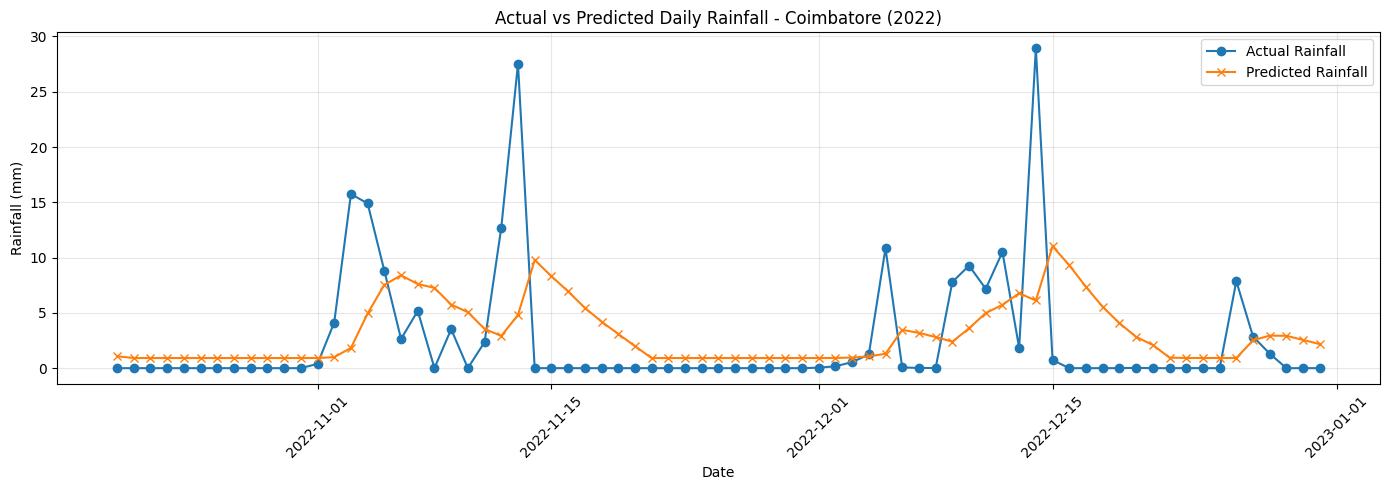

In [17]:

import matplotlib.pyplot as plt

# Test-period dates
test_dates = daily_df["date"].iloc[split_index:].reset_index(drop=True)

plt.figure(figsize=(14, 5))

plt.plot(
    test_dates,
    y_test_mm,
    label="Actual Rainfall",
    marker="o"
)

plt.plot(
    test_dates,
    pred_mm,
    label="Predicted Rainfall",
    marker="x"
)

plt.title("Actual vs Predicted Daily Rainfall - Coimbatore (2022)")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Use the latest 7 available days
last_7_days = rainfall_scaled[-7:].reshape(1, 7, 1)

# Predict next-day normalized rainfall
next_day_scaled = model.predict(last_7_days, verbose=0)

# Convert prediction back to millimeters
next_day_rainfall = scaler.inverse_transform(
    next_day_scaled
)[0, 0]

next_date = daily_df["date"].max() + pd.Timedelta(days=1)

print("Prediction date:", next_date.date())
print(f"Predicted rainfall: {max(0, next_day_rainfall):.2f} mm")


Prediction date: 2023-01-01
Predicted rainfall: 1.82 mm
